# Object-Oriented Programming (OOP) Lab
### Modelling the Real World with Classes and Objects

So far, our programs kept **data** (variables, lists, dictionaries) and the **functions** that work on that data separately. As programs grow, this becomes hard to manage. **Object-Oriented Programming** groups data and its functions together into **objects**, just as real-world things have both properties and behaviour.

**What you will learn**
1. What OOP is and why we need it
2. Classes and objects: how to create them
3. The constructor `__init__`
4. What `self` really means
5. Instance methods
6. Instance attributes vs class attributes, class methods and static methods
7. Special methods such as `__str__`
8. The four pillars of OOP: **Encapsulation, Inheritance, Polymorphism, Abstraction**
9. A final project: a library management system that uses everything from all the labs

**How to use this lab**
1. Run the cells **from top to bottom**; later cells use classes defined in earlier ones.
2. Compare your output with the **Expected output** comment in each cell.
3. Cells that use `input()` show a text box: type a value and press **Enter**.
4. Lines that would crash the program are **commented out**. Uncomment one to see the real error, then comment it again.

---
# Part 1: What is OOP?

**Object-Oriented Programming (OOP)** is a way of writing programs by grouping **data** and the **functions that work on that data** into one unit called an **object**.

**A real-world example: a car**
- **Data** (what it has): brand, colour, speed
- **Behaviour** (what it can do): start, accelerate, brake

In OOP, a `Car` object keeps its data and its behaviour **together**.

### The key words

| Term | Meaning | Car example |
|---|---|---|
| **Class** | A **blueprint** or template that describes what its objects will have and do | The design drawing of a car |
| **Object** (instance) | A real thing built from the class | Your red Maruti, my blue Hyundai |
| **Attribute** | Data stored inside an object (a variable that belongs to the object) | `colour = 'red'`, `speed = 0` |
| **Method** | A function written inside a class: something the object can do | `start()`, `brake()` |
| **Constructor** | A special method that runs **automatically** when an object is created, to set its starting attributes | Painting the car and fitting the engine as it leaves the factory |
| **self** | Inside a method, `self` means *this particular object* | This car, not every car |

### Procedural vs Object-Oriented

| Procedural (what we did so far) | Object-Oriented |
|---|---|
| The program is a list of functions | The program is a set of objects working together |
| Data and functions are separate | Data and functions are kept together |
| Focus: the **steps** to perform | Focus: the **things** (objects) and what they can do |
| Fine for small scripts | Better for large programs |

### Why use OOP?

| Benefit | Meaning |
|---|---|
| **Organisation** | Each class keeps related data and code in one place |
| **Reuse** | One class can create any number of objects; inheritance reuses whole classes |
| **Real-world modelling** | Students, bank accounts, products and orders map naturally to classes |
| **Safety** | Objects can protect their data from wrong changes |
| **Easy maintenance** | Change the class once and every object gets the change |

**Good news:** you have been using objects all along. Every value in Python is an object.

**Diagram: Procedural vs object-oriented**

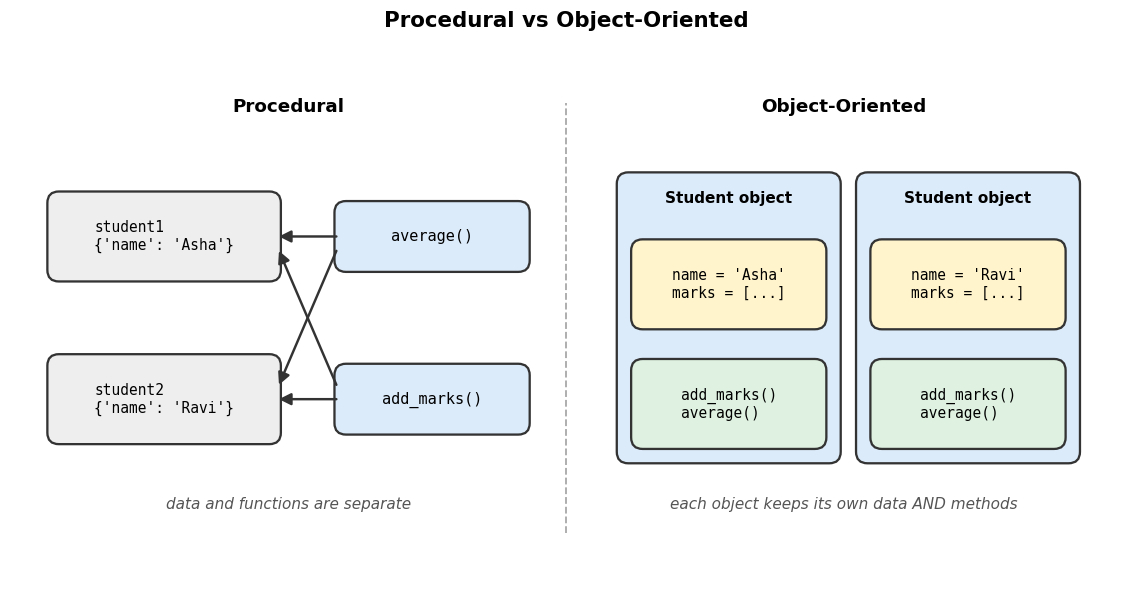

In [ ]:
# Example 1: You have already used objects and methods
text = 'python'
marks = [78, 92, 65]
print(type(text))       # text is an object of the class str
print(text.upper())     # upper() is a method of str objects
print(type(marks))      # marks is an object of the class list
marks.append(88)        # append() is a method of list objects
print(marks)
# Expected output:
# <class 'str'>
# PYTHON
# <class 'list'>
# [78, 92, 65, 88]

In [ ]:
# Example 2: The procedural way - data and functions are separate
student1 = {'name': 'Asha', 'marks': [78, 92]}
student2 = {'name': 'Ravi', 'marks': [65, 70]}

def average(student):
    return sum(student['marks']) / len(student['marks'])

def add_marks(student, mark):
    student['marks'].append(mark)

add_marks(student1, 85)
print(student1['name'], average(student1))
print(student2['name'], average(student2))
# Expected output:
# Asha 85.0
# Ravi 67.5

In [ ]:
# Example 3: The same program the OOP way (every line is explained in Parts 2 to 5)
class Student:
    def __init__(self, name, marks):
        self.name = name
        self.marks = marks

    def add_marks(self, mark):
        self.marks.append(mark)

    def average(self):
        return sum(self.marks) / len(self.marks)

student1 = Student('Asha', [78, 92])
student2 = Student('Ravi', [65, 70])
student1.add_marks(85)
print(student1.name, student1.average())
print(student2.name, student2.average())
# Expected output:
# Asha 85.0
# Ravi 67.5
# The data (name, marks) and the functions (add_marks, average) now travel together.

---
# Part 2: Classes and Objects

A **class** is a blueprint. An **object** is a thing built from that blueprint. One class can create **any number** of objects, and every object is separate from the others.

**Syntax:**
```python
class ClassName:
    # attributes and methods go here
    pass

object_name = ClassName()     # creating an object
```

**Rules and conventions**
- Start with the keyword `class`, then the name, then a colon `:`. The body is indented.
- Class names use **PascalCase**: every word starts with a capital letter and there are no underscores: `Student`, `BankAccount`, `LibraryItem`.
- You create an object by **calling the class like a function**: `Car()`. This is called **instantiation**.
- An object is also called an **instance** of its class.

**Diagram: One class, many objects**

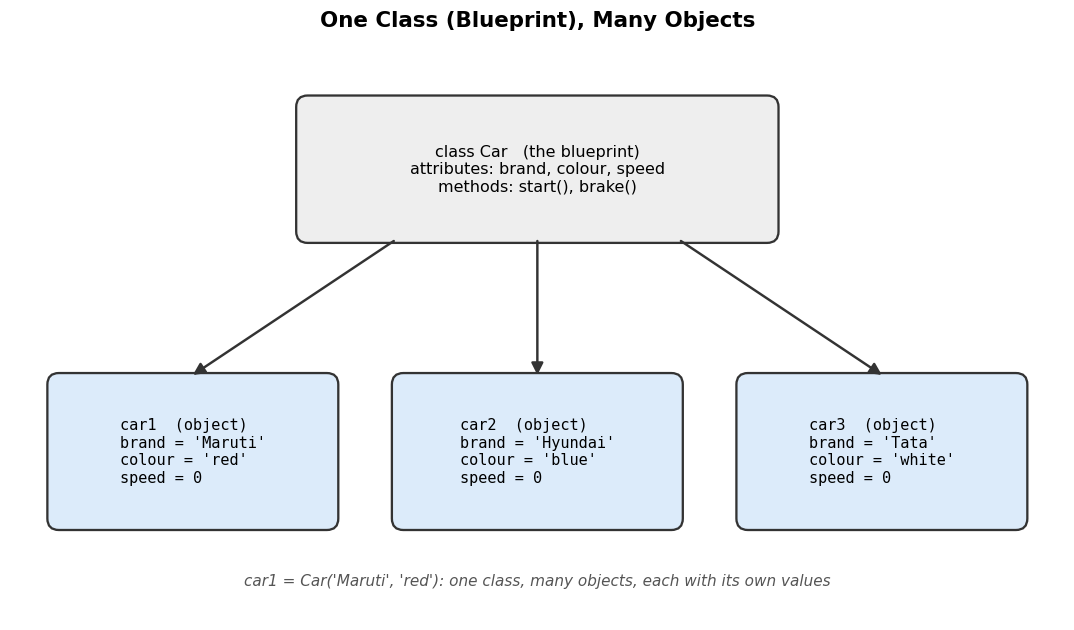

In [ ]:
# Example 1: The simplest class and two objects
class Car:
    pass            # an empty class, for now

car1 = Car()        # create an object
car2 = Car()        # create another object
print(type(car1))
print(car1 is car2)             # two separate objects
print(isinstance(car1, Car))    # is car1 an object of the class Car?
# Expected output:
# <class '__main__.Car'>
# False
# True

In [ ]:
# Example 2: Each object lives at its own place in memory
print(car1)
print(car2)
print(id(car1) == id(car2))
# Expected output:
# <__main__.Car object at 0x7f...>   (the numbers change every run)
# <__main__.Car object at 0x7f...>
# False

In [ ]:
# Example 3: Adding attributes to objects by hand (it works, but it is NOT the right way)
car1.brand = 'Maruti'
car1.colour = 'red'
car2.brand = 'Hyundai'           # oops: we forgot the colour
print(car1.brand, car1.colour)
print(car2.brand)
# print(car2.colour)             # AttributeError: 'Car' object has no attribute 'colour'
# Expected output:
# Maruti red
# Hyundai

**The problem with Example 3:** every object must be set up by hand, and it is easy to forget an attribute. The **constructor** (Part 3) fixes this: it sets up every new object automatically, in the same way, every time.

---
# Part 3: The Constructor - __init__

A **constructor** is a special method named `__init__` (two underscores on each side; say "dunder init"). Python **calls it automatically** every time an object is created. Its job is to give the new object its **starting attributes**.

**Syntax:**
```python
class Student:
    def __init__(self, name, age):     # the constructor
        self.name = name                # create the attribute 'name' on this object
        self.age = age

s1 = Student('Asha', 20)    # Python calls __init__ for you
```

**What happens when you write `Student('Asha', 20)`**
1. Python creates a new, empty `Student` object.
2. Python calls `__init__`, passing the new object as `self`, `'Asha'` as `name` and `20` as `age`.
3. `__init__` stores the values as attributes on the object: `self.name = name`.
4. The finished object is stored in the variable `s1`.

**Key points**
- The name must be exactly `__init__`, with two underscores on each side.
- The first parameter is always `self`.
- The arguments in `Student(...)` go to the parameters **after** `self`.
- In `self.name = name`, the left side is the object's attribute and the right side is the parameter. They often share a name.
- A constructor does not return anything; it only sets things up.

| Type | Parameters | Example |
|---|---|---|
| Default constructor | only `self` | `def __init__(self):` |
| Parameterised constructor | `self` plus others | `def __init__(self, name, age):` |
| No constructor written | Python supplies an empty one | `class Car: pass` |

**Diagram: What happens when you create an object**

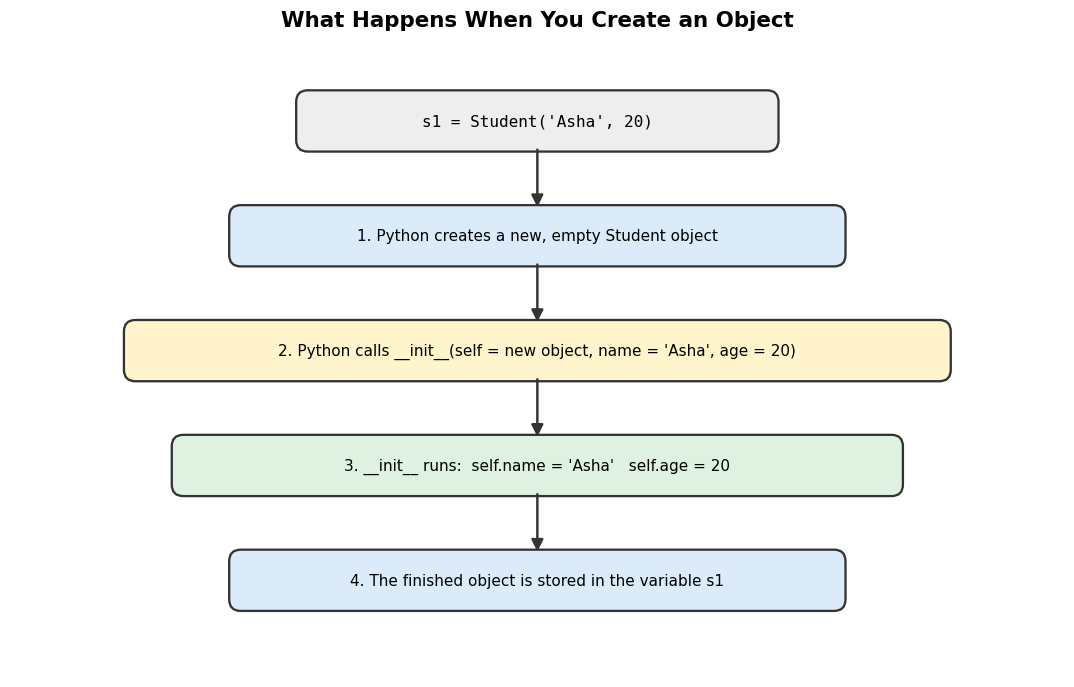

In [ ]:
# Example 1: A constructor that sets two attributes
class Student:
    def __init__(self, name, age):
        self.name = name
        self.age = age

s1 = Student('Asha', 20)
s2 = Student('Ravi', 22)
print(s1.name, s1.age)
print(s2.name, s2.age)
# Expected output:
# Asha 20
# Ravi 22

In [ ]:
# Example 2: The constructor runs automatically for every new object
class Car:
    def __init__(self, brand, colour):
        print(f'  Building a {colour} {brand}...')
        self.brand = brand
        self.colour = colour
        self.speed = 0                 # every car starts at speed 0 (not a parameter)

car1 = Car('Maruti', 'red')
car2 = Car('Hyundai', 'blue')
print(car1.brand, car1.colour, car1.speed)
print(car2.brand, car2.colour, car2.speed)
# Expected output:
#   Building a red Maruti...
#   Building a blue Hyundai...
# Maruti red 0
# Hyundai blue 0

In [ ]:
# Example 3: A default constructor - no parameters except self
class Counter:
    def __init__(self):
        self.count = 0

c = Counter()
print(c.count)
# Expected output: 0

In [ ]:
# Example 4: Default parameter values in the constructor
class BankAccount:
    def __init__(self, owner, balance=0, account_type='Savings'):
        self.owner = owner
        self.balance = balance
        self.account_type = account_type

a1 = BankAccount('Asha')
a2 = BankAccount('Ravi', 5000, 'Current')
a3 = BankAccount('Meena', account_type='Current')
print(a1.owner, a1.balance, a1.account_type)
print(a2.owner, a2.balance, a2.account_type)
print(a3.owner, a3.balance, a3.account_type)
# Expected output:
# Asha 0 Savings
# Ravi 5000 Current
# Meena 0 Current

In [ ]:
# Example 5: The constructor can calculate attributes from the arguments
class Rectangle:
    def __init__(self, length, width):
        self.length = length
        self.width = width
        self.area = length * width          # calculated once, when the object is created

r = Rectangle(5, 3)
print(r.length, r.width, r.area)
# Expected output: 5 3 15

In [ ]:
# Example 6: Checking values in the constructor (raise, from the Exception Handling lab)
class Product:
    def __init__(self, name, price):
        if price < 0:
            raise ValueError(f'price cannot be negative, got {price}')
        self.name = name
        self.price = price

p = Product('Pen', 10)
print(p.name, p.price)
try:
    bad = Product('Bag', -50)
except ValueError as e:
    print('Could not create the product:', e)
# Expected output:
# Pen 10
# Could not create the product: price cannot be negative, got -50

In [ ]:
# Example 7: Common constructor mistakes
# s = Student('Asha')        # TypeError: Student.__init__() missing 1 required positional argument: 'age'
# def _init_(self, name):    # ONE underscore: Python never calls it, so the attributes are never created
# def __int__(self, name):   # a typo (int instead of init): the same problem
print('The arguments in Student(...) must match the parameters after self')
# Expected output: The arguments in Student(...) must match the parameters after self

---
# Part 4: Understanding self

`self` is **the object that the method is working on right now**.

When you call `s1.introduce()`, Python automatically passes `s1` as the first argument:
```python
s1.introduce()          # what you write
Student.introduce(s1)   # what Python actually does
```
So inside the method, `self` **is** `s1`. When you call `s2.introduce()`, `self` is `s2`. That is how **one** method works correctly for **every** object.

**Key points**
- `self` must be the **first parameter** of every instance method, including `__init__`.
- You never pass `self` yourself; Python does it.
- `self.name` means *the name attribute of this object*. A plain `name` inside a method is just a local variable.
- `self` is a strong convention, not a keyword. Any name would work, but always use `self`.

**Diagram: What self is**

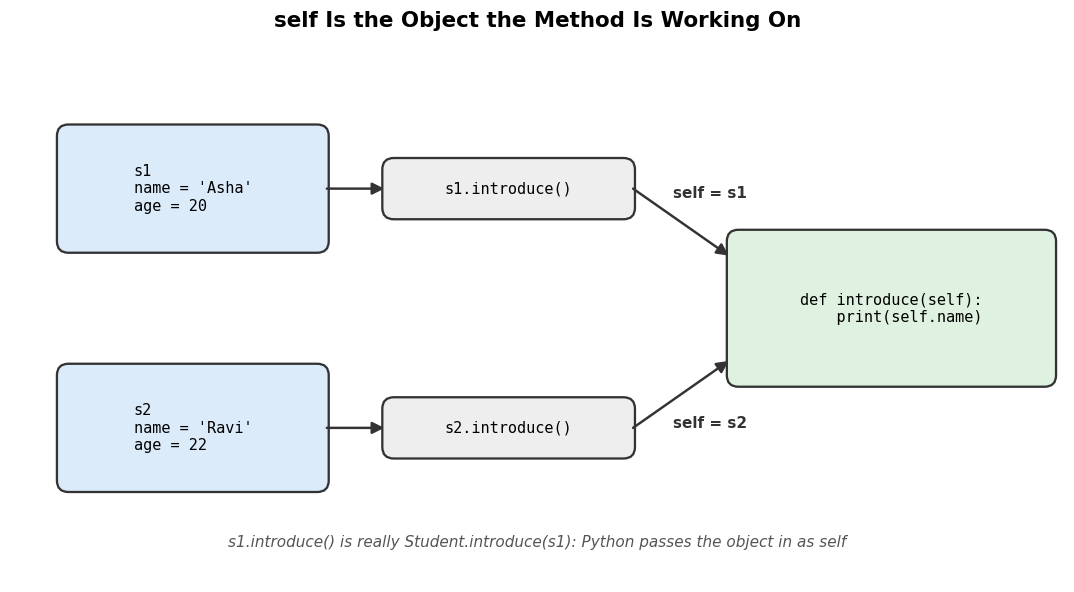

In [ ]:
# Example 1: self is the object the method is called on
class Student:
    def __init__(self, name, age):
        self.name = name
        self.age = age

    def introduce(self):
        print(f'Hi, I am {self.name} and I am {self.age} years old.')

s1 = Student('Asha', 20)
s2 = Student('Ravi', 22)
s1.introduce()            # here self is s1
s2.introduce()            # here self is s2
# Expected output:
# Hi, I am Asha and I am 20 years old.
# Hi, I am Ravi and I am 22 years old.

In [ ]:
# Example 2: obj.method() is the same as ClassName.method(obj)
s1.introduce()
Student.introduce(s1)     # Python turns the first line into this one
# Expected output:
# Hi, I am Asha and I am 20 years old.
# Hi, I am Asha and I am 20 years old.

In [ ]:
# Example 3: Proof - self and the object are the very same thing
class Demo:
    def show_self(self):
        print('id of self:', id(self))

d = Demo()
print('id of d:   ', id(d))
d.show_self()
# Expected output (the numbers change every run, but both lines show the SAME number):
# id of d:    140231...
# id of self: 140231...

In [ ]:
# Example 4: Forgetting self - two common mistakes
class Greeter:
    def __init__(self, name):
        self.name = name

    def greet_wrong():                 # mistake 1: self is missing from the parameters
        print('Hello')

    def greet_also_wrong(self):
        print('Hello', name)           # mistake 2: name instead of self.name

    def greet(self):
        print('Hello', self.name)      # correct

g = Greeter('Meena')
g.greet()
# g.greet_wrong()        # TypeError: Greeter.greet_wrong() takes 0 positional arguments but 1 was given
# g.greet_also_wrong()   # NameError: name 'name' is not defined (or, worse, it uses some other global 'name')
# Expected output: Hello Meena

---
# Part 5: Instance Methods

Methods are functions written inside a class. Every object keeps its **own state** (its attribute values), and methods read or change that state.

| Kind of method | Purpose | Example |
|---|---|---|
| Modifier (setter-style) | Change the object's attributes | `deposit(amount)`, `add_marks(mark)` |
| Reporting / getter | Return or show information | `get_balance()`, `report()` |
| Calculating | Return a computed result | `area()`, `average()` |
| Helper | Called by other methods through `self.method()` | `self.average()` inside `grade()` |

Methods can take parameters, use `if`, loops and `return`, call other methods, and even receive **other objects** as arguments.

In [ ]:
# Example 1: Methods that change the object's state
class BankAccount:
    def __init__(self, owner, balance=0):
        self.owner = owner
        self.balance = balance

    def deposit(self, amount):
        self.balance += amount
        print(f'{self.owner} deposited {amount}. Balance: {self.balance}')

    def withdraw(self, amount):
        if amount > self.balance:
            print(f'{self.owner}: insufficient balance ({self.balance})')
            return
        self.balance -= amount
        print(f'{self.owner} withdrew {amount}. Balance: {self.balance}')

acc1 = BankAccount('Asha', 1000)
acc2 = BankAccount('Ravi')
acc1.deposit(500)
acc1.withdraw(200)
acc2.withdraw(100)
print(acc1.balance, acc2.balance)      # each object keeps its own balance
# Expected output:
# Asha deposited 500. Balance: 1500
# Asha withdrew 200. Balance: 1300
# Ravi: insufficient balance (0)
# 1300 0

In [ ]:
# Example 2: Methods that return values
class Rectangle:
    def __init__(self, length, width):
        self.length = length
        self.width = width

    def area(self):
        return self.length * self.width

    def perimeter(self):
        return 2 * (self.length + self.width)

    def is_square(self):
        return self.length == self.width

r1 = Rectangle(5, 3)
r2 = Rectangle(4, 4)
print(r1.area(), r1.perimeter(), r1.is_square())
print(r2.area(), r2.perimeter(), r2.is_square())
# Expected output:
# 15 16 False
# 16 16 True

In [ ]:
# Example 3: A method can call other methods of the same object with self
class Student:
    def __init__(self, name, marks):
        self.name = name
        self.marks = marks

    def average(self):
        return sum(self.marks) / len(self.marks)

    def grade(self):
        avg = self.average()            # calling another method of this object
        if avg >= 90:
            return 'A'
        elif avg >= 75:
            return 'B'
        elif avg >= 50:
            return 'C'
        return 'F'

    def report(self):
        print(f'{self.name}: average {self.average():.1f}, grade {self.grade()}')

Student('Asha', [91, 88, 95]).report()
Student('Ravi', [62, 70, 58]).report()
# Expected output:
# Asha: average 91.3, grade A
# Ravi: average 63.3, grade C

In [ ]:
# Example 4: A list of objects - loops, max() and lambda work with objects too
students = [Student('Asha', [91, 88, 95]),
            Student('Ravi', [62, 70, 58]),
            Student('Meena', [78, 82, 80])]
for s in students:
    s.report()
topper = max(students, key=lambda s: s.average())
print('Topper:', topper.name)
# Expected output:
# Asha: average 91.3, grade A
# Ravi: average 63.3, grade C
# Meena: average 80.0, grade B
# Topper: Asha

In [ ]:
# Example 5: Objects working together - a method that receives another object
class Wallet:
    def __init__(self, owner, money):
        self.owner = owner
        self.money = money

    def pay(self, other, amount):
        """Move money from this wallet to another Wallet object."""
        if amount > self.money:
            print(f'{self.owner} does not have {amount}')
            return
        self.money -= amount
        other.money += amount
        print(f'{self.owner} paid {amount} to {other.owner}')

w1 = Wallet('Asha', 500)
w2 = Wallet('Ravi', 100)
w1.pay(w2, 200)
w2.pay(w1, 1000)
print(w1.owner, w1.money, '|', w2.owner, w2.money)
# Expected output:
# Asha paid 200 to Ravi
# Ravi does not have 1000
# Asha 300 | Ravi 300

In [ ]:
# Example 6: Looking inside an object
print(vars(w1))                     # all the attributes of the object, as a dictionary
print(hasattr(w1, 'money'), hasattr(w1, 'age'))
w1.money = 999                      # attributes can be changed directly (Part 9 shows how to protect them)
print(w1.money)
# Expected output:
# {'owner': 'Asha', 'money': 300}
# True False
# 999

---
# Part 6: Instance Attributes vs Class Attributes

| | Instance attribute | Class attribute |
|---|---|---|
| Where it is created | Inside a method, with `self.name = ...` | Directly in the class body, outside any method |
| Belongs to | One object | The class: **shared** by all its objects |
| Example | Each student's `name` | The `school` all students attend, a counter of objects |
| How to use it | `obj.name` | `ClassName.attribute` (objects can also read it) |

### Three kinds of methods

| Kind | First parameter | Written with | Can use | Typical use |
|---|---|---|---|---|
| Instance method | `self` | nothing extra | the object's and the class's data | most methods |
| Class method | `cls` (the class) | `@classmethod` | the class's data | counters, alternative ways to create objects |
| Static method | none | `@staticmethod` | only its own arguments | helper functions that belong with the class |

A line starting with `@`, written just above a method, is called a **decorator**. It changes how the method works.

**Diagram: Class attributes vs instance attributes**

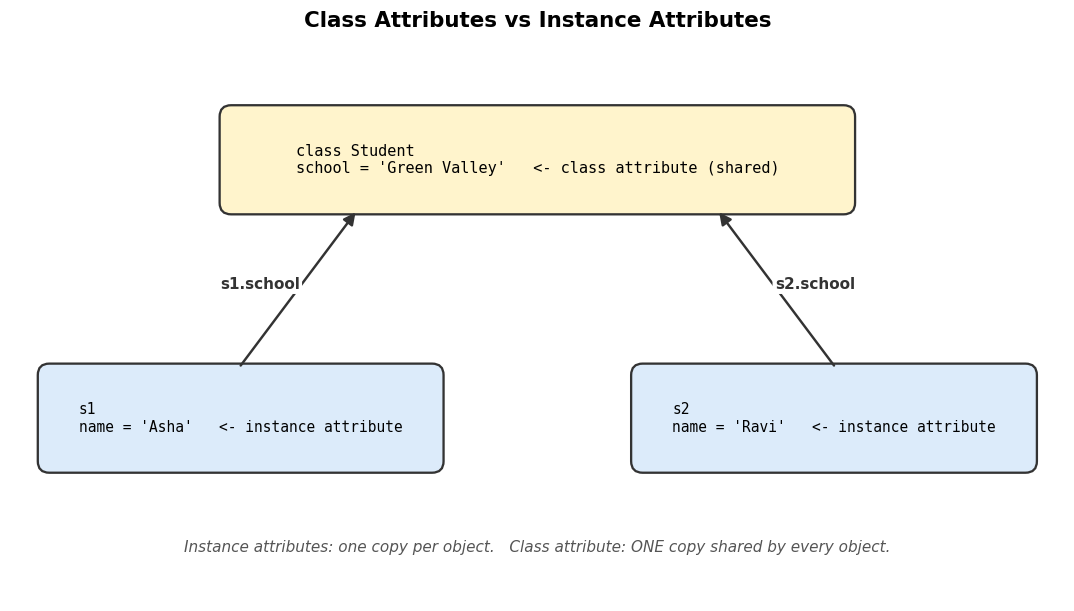

In [ ]:
# Example 1: A class attribute is shared by all objects
class Student:
    school = 'Green Valley School'      # class attribute: one copy for everyone

    def __init__(self, name):
        self.name = name                 # instance attribute: one per object

s1 = Student('Asha')
s2 = Student('Ravi')
print(s1.name, '-', s1.school)
print(s2.name, '-', s2.school)
Student.school = 'Sunrise Public School'      # change it once, on the class...
print(s1.school, '|', s2.school)              # ...and every object sees the change
# Expected output:
# Asha - Green Valley School
# Ravi - Green Valley School
# Sunrise Public School | Sunrise Public School

In [ ]:
# Example 2: Counting objects with a class attribute
class Employee:
    count = 0                            # how many employees exist

    def __init__(self, name):
        self.name = name
        Employee.count += 1              # update the CLASS attribute
        self.emp_id = Employee.count     # each employee gets the next ID

e1 = Employee('Asha')
e2 = Employee('Ravi')
e3 = Employee('Meena')
print('Employees:', Employee.count)
print(e1.name, e1.emp_id, '|', e3.name, e3.emp_id)
# Expected output:
# Employees: 3
# Asha 1 | Meena 3

In [ ]:
# Example 3: Trap - assigning through an object creates a NEW instance attribute
s1.school = 'My Own School'         # only s1 gets its own 'school' attribute
print(s1.school)
print(s2.school)                    # s2 still reads the class attribute
print(Student.school)
# Expected output:
# My Own School
# Sunrise Public School
# Sunrise Public School

In [ ]:
# Example 4: Class methods and static methods
class Pizza:
    made = 0                                  # class attribute

    def __init__(self, size, toppings):
        self.size = size
        self.toppings = toppings
        Pizza.made += 1

    @classmethod
    def margherita(cls, size):
        """Alternative constructor: a ready-made recipe."""
        return cls(size, ['cheese', 'tomato'])

    @classmethod
    def total_made(cls):
        return cls.made

    @staticmethod
    def is_valid_size(size):
        """A helper that needs no object and no class data."""
        return size in ['small', 'medium', 'large']

p1 = Pizza('large', ['onion', 'corn'])
p2 = Pizza.margherita('medium')            # created by the class method
print(p2.size, p2.toppings)
print('Pizzas made:', Pizza.total_made())
print(Pizza.is_valid_size('medium'), Pizza.is_valid_size('huge'))
# Expected output:
# medium ['cheese', 'tomato']
# Pizzas made: 2
# True False

In [ ]:
# Example 5: A class method that builds an object from a line of text (useful with files)
class Person:
    def __init__(self, name, age):
        self.name = name
        self.age = age

    @classmethod
    def from_line(cls, line):
        """Create a Person from a line like 'Asha,20'."""
        name, age = line.strip().split(',')
        return cls(name, int(age))

lines = ['Asha,20\n', 'Ravi,22\n']      # as if read from a text file
people = []
for line in lines:
    people.append(Person.from_line(line))
for p in people:
    print(p.name, 'will be', p.age + 1, 'next year')
# Expected output:
# Asha will be 21 next year
# Ravi will be 23 next year

In [ ]:
# Example 6: Trap - a list as a class attribute is shared by EVERY object
class Team:
    members = []                      # WRONG: one list for all teams

    def __init__(self, name):
        self.name = name

    def add(self, person):
        self.members.append(person)

class FixedTeam:
    def __init__(self, name):
        self.name = name
        self.members = []             # RIGHT: a new list for each team

    def add(self, person):
        self.members.append(person)

team_a = Team('A')
team_b = Team('B')
team_a.add('Asha')
print(team_b.members)                 # surprise: team B also has Asha

team_x = FixedTeam('X')
team_y = FixedTeam('Y')
team_x.add('Asha')
print(team_y.members)
# Expected output:
# ['Asha']
# []

---
# Part 7: Special Methods - __str__ and Friends

**Special methods** (also called magic or **dunder** methods) have names with double underscores. You do not call them directly; Python calls them **automatically** in certain situations.

| Method | Called automatically when | Example |
|---|---|---|
| `__init__(self, ...)` | an object is created | `Student('Asha', 20)` |
| `__str__(self)` | you `print(obj)` or use `str(obj)` | `print(s1)` |
| `__repr__(self)` | the object is shown inside a list, or in the shell | `print([p1, p2])` |
| `__len__(self)` | you call `len(obj)` | `len(playlist)` |
| `__eq__(self, other)` | you compare `obj1 == obj2` | `p1 == p2` |
| `__add__(self, other)` | you write `obj1 + obj2` | Part 11 |

`__str__` and `__repr__` must **return** a string (not print it).

In [ ]:
# Example 1: Without __str__, print shows a memory address; with __str__ it shows something useful
class Book:
    def __init__(self, title, author):
        self.title = title
        self.author = author

class BetterBook:
    def __init__(self, title, author):
        self.title = title
        self.author = author

    def __str__(self):
        return f'{self.title} by {self.author}'

print(Book('The Silent River', 'K. Menon'))
print(BetterBook('The Silent River', 'K. Menon'))
# Expected output:
# <__main__.Book object at 0x...>
# The Silent River by K. Menon

In [ ]:
# Example 2: __repr__ is used when objects are shown inside a list
class Point:
    def __init__(self, x, y):
        self.x = x
        self.y = y

    def __repr__(self):
        return f'Point({self.x}, {self.y})'

points = [Point(1, 2), Point(3, 4)]
print(points)
print(points[0])            # with no __str__, print() uses __repr__ as well
# Expected output:
# [Point(1, 2), Point(3, 4)]
# Point(1, 2)

In [ ]:
# Example 3: __len__ and __eq__
class Playlist:
    def __init__(self, name, songs):
        self.name = name
        self.songs = songs

    def __len__(self):
        return len(self.songs)

    def __eq__(self, other):
        return self.songs == other.songs

p1 = Playlist('Morning', ['Song A', 'Song B', 'Song C'])
p2 = Playlist('Gym', ['Song A', 'Song B', 'Song C'])
p3 = Playlist('Night', ['Song D'])
print(len(p1), len(p3))
print(p1 == p2, p1 == p3)
# Expected output:
# 3 1
# True False

---
# Part 8: The Four Pillars of OOP

The **four pillars** are the four big ideas that make OOP powerful.

| Pillar | Meaning in one line | Real-life example | Python tools |
|---|---|---|---|
| **Encapsulation** (Part 9) | Bundle data with its methods, and **protect** the data from wrong changes | An ATM: you get cash through its buttons, you cannot open the cash box | `_protected`, `__private`, getters and setters, `@property` |
| **Inheritance** (Part 10) | A new class **reuses** the attributes and methods of an existing class | A child inherits features from parents; an electric car **is a** car | `class Child(Parent):`, `super()` |
| **Polymorphism** (Part 11) | **"Many forms"**: the same method name behaves differently for different objects | The word *open* means different things for a door, a file and a shop | method overriding, duck typing, operator overloading |
| **Abstraction** (Part 12) | Show only what is **necessary** and hide the complex details | You drive a car with a steering wheel and pedals without knowing how the engine works | abstract classes: `ABC`, `@abstractmethod` |

This lab covers them in this order, because abstract classes use inheritance.

A popular way to remember them: **A PIE** (Abstraction, Polymorphism, Inheritance, Encapsulation).

**Diagram: The four pillars of OOP**

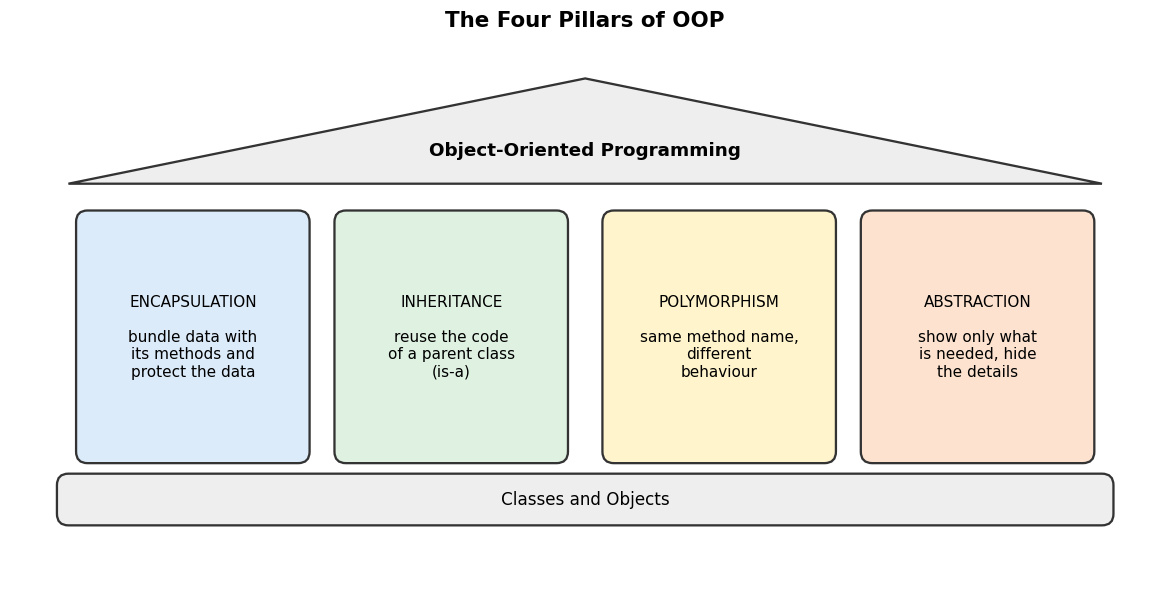

---
# Part 9: Encapsulation

Encapsulation means two things:
1. **Bundling:** keep the data (attributes) and the methods that use them together in one class. You have done this since Part 3.
2. **Data hiding:** stop outside code from changing the data in a wrong way. Outside code should go through the object's **methods**, which can check the values first.

Python has no strict *private* keyword like Java. It uses **naming conventions**:

| Name | Kind | Meaning |
|---|---|---|
| `balance` | Public | Anyone can read and change it |
| `_balance` | Protected (one underscore) | A polite message: *for internal use, please do not touch from outside*. Python does not stop you |
| `__balance` | Private (two underscores) | Python **renames** it to `_ClassName__balance` (**name mangling**), so `obj.__balance` from outside gives an `AttributeError` |

**Getters and setters:** methods that read (`get_balance()`) and change private data safely, with checks.

**`@property`:** the Pythonic way. You use `obj.marks` like a normal attribute, while a method runs behind the scenes to check the value.

**Diagram: Encapsulation**

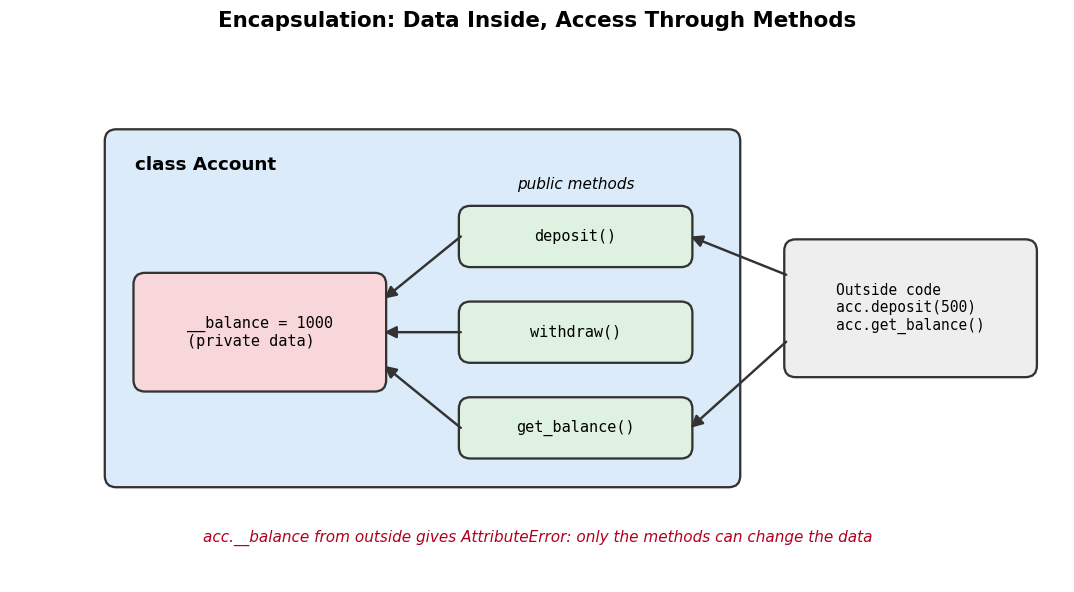

In [ ]:
# Example 1: The problem - anyone can put wrong data into a public attribute
class Account:
    def __init__(self, owner, balance):
        self.owner = owner
        self.balance = balance          # public

acc = Account('Asha', 1000)
acc.balance = -50000                     # nothing stops this mistake
print(acc.balance)
# Expected output: -50000

In [ ]:
# Example 2: A protected attribute (one underscore) - only a polite 'do not touch'
class Account:
    def __init__(self, owner, balance):
        self.owner = owner
        self._balance = balance         # protected: meant for internal use

acc = Account('Asha', 1000)
print(acc._balance)                     # still works: it is only a convention
# Expected output: 1000

In [ ]:
# Example 3: A private attribute (two underscores) with getter and setter-style methods
class Account:
    def __init__(self, owner, balance=0):
        self.owner = owner
        self.__balance = balance        # private

    def get_balance(self):              # getter: read safely
        return self.__balance

    def deposit(self, amount):          # change safely, with a check
        if amount <= 0:
            print('  Deposit must be positive')
            return
        self.__balance += amount

    def withdraw(self, amount):
        if amount > self.__balance:
            print('  Insufficient balance')
            return
        self.__balance -= amount

acc = Account('Asha', 1000)
acc.deposit(500)
acc.deposit(-100)
acc.withdraw(5000)
print('Balance:', acc.get_balance())
# print(acc.__balance)     # AttributeError: 'Account' object has no attribute '__balance'
# Expected output:
#   Deposit must be positive
#   Insufficient balance
# Balance: 1500

In [ ]:
# Example 4: Name mangling - what Python really did with __balance
print(vars(acc))
print(acc._Account__balance)       # possible, but NEVER do this in real code
acc.__balance = 0                  # outside the class this creates a NEW, unrelated attribute
print(acc.get_balance())           # the real balance is safe
# Expected output:
# {'owner': 'Asha', '_Account__balance': 1500}
# 1500
# 1500

In [ ]:
# Example 5: @property - methods that are used like attributes (the Pythonic way)
class Student:
    def __init__(self, name, marks):
        self.name = name
        self.marks = marks              # this line already goes through the setter below

    @property
    def marks(self):                    # getter: runs when you READ student.marks
        return self.__marks

    @marks.setter
    def marks(self, value):             # setter: runs when you WRITE student.marks = ...
        if value < 0 or value > 100:
            raise ValueError(f'marks must be between 0 and 100, got {value}')
        self.__marks = value

    @property
    def result(self):                   # a read-only, calculated property
        return 'Pass' if self.__marks >= 40 else 'Fail'

s = Student('Asha', 85)
print(s.name, s.marks, s.result)       # no () - they look like attributes
s.marks = 35
print(s.marks, s.result)
try:
    s.marks = 150
except ValueError as e:
    print('Rejected:', e)
# s.result = 'Pass'     # AttributeError: property 'result' of 'Student' object has no setter
# Expected output:
# Asha 85 Pass
# 35 Fail
# Rejected: marks must be between 0 and 100, got 150

---
# Part 10: Inheritance

**Inheritance** lets a new class (the **child**, subclass or derived class) reuse the attributes and methods of an existing class (the **parent**, superclass or base class), and add or change what it needs.

It models an **"is a"** relationship: a Dog **is an** Animal; a Student **is a** Person.

**Syntax:**
```python
class Parent:
    ...

class Child(Parent):       # Child inherits everything from Parent
    ...
```

| Idea | Meaning |
|---|---|
| **Reuse** | The child gets all the parent's methods without rewriting them |
| **Extend** | The child can add new attributes and methods |
| **Override** | The child can write its own version of a parent method |
| **super()** | Calls the parent's version of a method, most often `super().__init__(...)` in the child's constructor |

### Types of inheritance

| Type | Shape | Example |
|---|---|---|
| Single | one parent, one child | Animal -> Dog |
| Multilevel | grandparent -> parent -> child | Vehicle -> Car -> ElectricCar |
| Hierarchical | one parent, many children | Person -> Student, Teacher |
| Multiple | many parents, one child | Camera + Phone -> SmartPhone |
| Hybrid | a mix of the above | |

Every class you write already inherits from Python's built-in class `object`.

**Diagram: Types of inheritance**

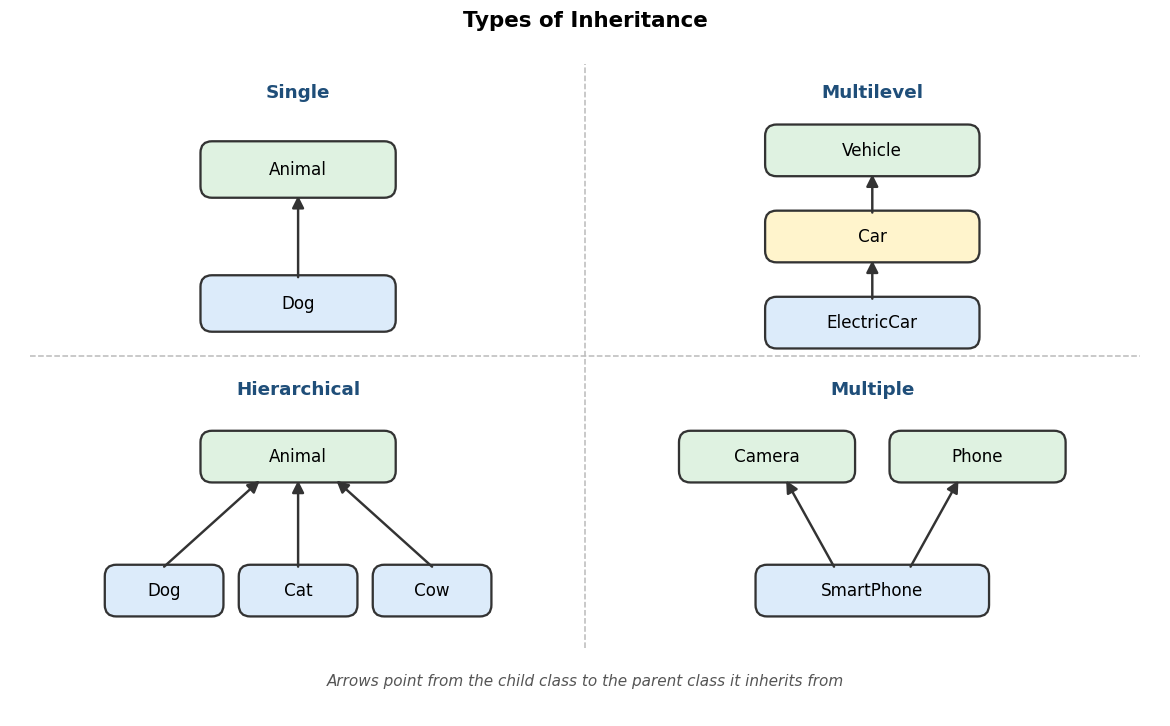

In [ ]:
# Example 1: Single inheritance - the child reuses the parent's methods
class Animal:
    def __init__(self, name):
        self.name = name

    def eat(self):
        print(f'{self.name} is eating')

    def sleep(self):
        print(f'{self.name} is sleeping')

class Dog(Animal):          # Dog inherits from Animal
    def bark(self):         # extend: a new method that only dogs have
        print(f'{self.name} says Woof!')

d = Dog('Tommy')
d.eat()                     # inherited from Animal
d.sleep()                   # inherited from Animal
d.bark()                    # Dog's own method
# Expected output:
# Tommy is eating
# Tommy is sleeping
# Tommy says Woof!

In [ ]:
# Example 2: super().__init__() - the children add their own attributes (hierarchical inheritance)
class Person:
    def __init__(self, name, age):
        self.name = name
        self.age = age

    def introduce(self):
        print(f'I am {self.name}, {self.age} years old.')

class Student(Person):
    def __init__(self, name, age, roll_no):
        super().__init__(name, age)      # let Person set name and age
        self.roll_no = roll_no           # then add what is new

class Teacher(Person):
    def __init__(self, name, age, subject):
        super().__init__(name, age)
        self.subject = subject

s = Student('Asha', 20, 101)
t = Teacher('Mr. Rao', 45, 'Maths')
s.introduce()
t.introduce()
print(s.roll_no, t.subject)
# Expected output:
# I am Asha, 20 years old.
# I am Mr. Rao, 45 years old.
# 101 Maths

In [ ]:
# Example 3: Overriding - the child replaces a parent method, and can still call it with super()
class Student(Person):
    def __init__(self, name, age, roll_no):
        super().__init__(name, age)
        self.roll_no = roll_no

    def introduce(self):                  # overrides Person.introduce
        super().introduce()               # first run the parent's version
        print(f'My roll number is {self.roll_no}.')

Student('Ravi', 19, 102).introduce()
Person('Meena', 40).introduce()           # the parent class is unchanged
# Expected output:
# I am Ravi, 19 years old.
# My roll number is 102.
# I am Meena, 40 years old.

In [ ]:
# Example 4: Multilevel inheritance - Vehicle -> Car -> ElectricCar
class Vehicle:
    def __init__(self, brand):
        self.brand = brand

    def start(self):
        print(f'{self.brand} vehicle started')

class Car(Vehicle):
    def __init__(self, brand, seats):
        super().__init__(brand)
        self.seats = seats

    def describe(self):
        print(f'{self.brand} car with {self.seats} seats')

class ElectricCar(Car):
    def __init__(self, brand, seats, battery_kwh):
        super().__init__(brand, seats)
        self.battery_kwh = battery_kwh

    def charge(self):
        print(f'Charging the {self.battery_kwh} kWh battery')

ev = ElectricCar('Tata', 5, 40)
ev.start()        # from Vehicle (the grandparent)
ev.describe()     # from Car (the parent)
ev.charge()       # its own method
# Expected output:
# Tata vehicle started
# Tata car with 5 seats
# Charging the 40 kWh battery

In [ ]:
# Example 5: Multiple inheritance - one child, two parents
class Camera:
    def take_photo(self):
        print('Click! Photo taken')

class Phone:
    def call(self, number):
        print(f'Calling {number}...')

class SmartPhone(Camera, Phone):
    pass

sp = SmartPhone()
sp.take_photo()
sp.call('98765-43210')
print(SmartPhone.__mro__)     # Method Resolution Order: where Python looks for a method, in order
# Expected output:
# Click! Photo taken
# Calling 98765-43210...
# (<class '__main__.SmartPhone'>, <class '__main__.Camera'>, <class '__main__.Phone'>, <class 'object'>)

In [ ]:
# Example 6: isinstance() and issubclass() understand inheritance
s = Student('Asha', 20, 101)
print(isinstance(s, Student), isinstance(s, Person))   # a Student IS a Person
print(isinstance(s, Teacher))
print(issubclass(Student, Person), issubclass(Person, Student))
print(issubclass(Dog, object))        # every class inherits from object
# Expected output:
# True True
# False
# True False
# True

In [ ]:
# Example 7: Common mistake - forgetting super().__init__()
class Manager(Person):
    def __init__(self, name, age, team):
        self.team = team                  # forgot: super().__init__(name, age)

m = Manager('Kiran', 38, 'Sales')
print(m.team)
# m.introduce()     # AttributeError: 'Manager' object has no attribute 'name'
# Expected output: Sales

---
# Part 11: Polymorphism

**Polymorphism** means **"many forms"**: the **same method name or operator** works differently depending on the object it is used with.

| Form | Meaning | Example |
|---|---|---|
| Built-in polymorphism | Built-in functions and operators work on many types | `len('hi')`, `len([1, 2])`; `+` adds numbers and joins strings |
| Method overriding | Child classes give their own version of a parent method | `Dog.speak()`, `Cat.speak()` |
| Duck typing | If an object has the method, Python calls it; its class does not matter. *If it walks like a duck and quacks like a duck, it is a duck.* | Unrelated classes that all have `move()` |
| Operator overloading | Special methods let your objects use operators | `__add__` for `+`, `__gt__` for `>` |

**Note:** Python has **no method overloading** (two methods with the same name but different parameters, as in Java). If you define a method twice, the last one wins. Use default arguments or `*args` instead.

**Diagram: Polymorphism**

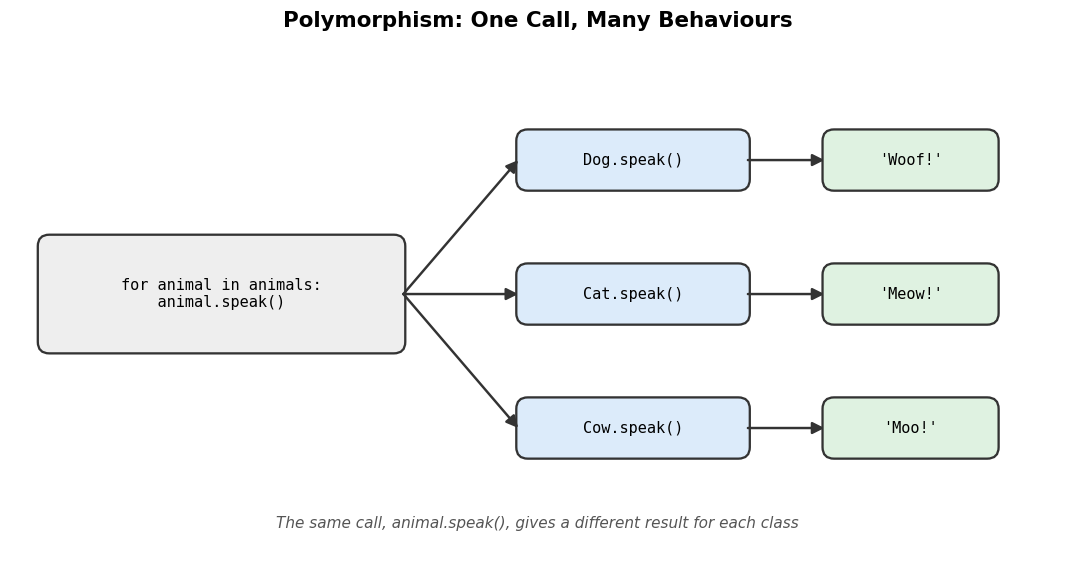

In [ ]:
# Example 1: Polymorphism you already know
print(len('Python'), len([1, 2, 3]), len({'a': 1}))
print(5 + 3, 'Py' + 'thon', [1] + [2])
# Expected output:
# 6 3 1
# 8 Python [1, 2]

In [ ]:
# Example 2: Method overriding - one loop, many behaviours
class Animal:
    def __init__(self, name):
        self.name = name

    def speak(self):
        return '...'

class Dog(Animal):
    def speak(self):
        return 'Woof!'

class Cat(Animal):
    def speak(self):
        return 'Meow!'

class Cow(Animal):
    def speak(self):
        return 'Moo!'

animals = [Dog('Tommy'), Cat('Kitty'), Cow('Gauri'), Animal('Unknown')]
for animal in animals:
    print(f'{animal.name}: {animal.speak()}')      # the same call, different results
# Expected output:
# Tommy: Woof!
# Kitty: Meow!
# Gauri: Moo!
# Unknown: ...

In [ ]:
# Example 3: A real-world example - several payment methods, one checkout function
class Payment:
    def __init__(self, amount):
        self.amount = amount

    def pay(self):
        print(f'Paying {self.amount}')

class UPIPayment(Payment):
    def pay(self):
        print(f'Paid Rs. {self.amount} using UPI')

class CardPayment(Payment):
    def pay(self):
        fee = self.amount * 2 / 100
        print(f'Paid Rs. {self.amount} by card (+ Rs. {fee} fee)')

class CashPayment(Payment):
    def pay(self):
        print(f'Collect Rs. {self.amount} in cash at delivery')

def checkout(payment):          # works with ANY kind of payment object
    payment.pay()

for p in [UPIPayment(500), CardPayment(1000), CashPayment(250)]:
    checkout(p)
# Expected output:
# Paid Rs. 500 using UPI
# Paid Rs. 1000 by card (+ Rs. 20.0 fee)
# Collect Rs. 250 in cash at delivery

In [ ]:
# Example 4: Duck typing - the classes are NOT related; only the method name matters
class Bird:
    def move(self):
        return 'flies in the sky'

class Fish:
    def move(self):
        return 'swims in the water'

class Robot:
    def move(self):
        return 'rolls on wheels'

for thing in [Bird(), Fish(), Robot()]:
    print(type(thing).__name__, thing.move())
# Expected output:
# Bird flies in the sky
# Fish swims in the water
# Robot rolls on wheels

In [ ]:
# Example 5: Operator overloading - teach + and > to work with your own objects
class Money:
    def __init__(self, rupees):
        self.rupees = rupees

    def __add__(self, other):          # called for: money1 + money2
        return Money(self.rupees + other.rupees)

    def __gt__(self, other):           # called for: money1 > money2
        return self.rupees > other.rupees

    def __str__(self):
        return f'Rs. {self.rupees}'

wallet = Money(500)
salary = Money(25000)
total = wallet + salary
print(total)
print(salary > wallet)
# Expected output:
# Rs. 25500
# True

In [ ]:
# Example 6: No method overloading in Python - use a default argument instead
class Calculator:
    def add(self, a, b, c=0):          # one method handles 2 or 3 numbers
        return a + b + c

calc = Calculator()
print(calc.add(2, 3), calc.add(2, 3, 4))
# Writing a second add() in the class would simply replace the first one.
# Expected output: 5 9

---
# Part 12: Abstraction

**Abstraction** means showing only the **essential features** and hiding the complicated details.

It works at two levels:
1. **Hiding details behind simple methods:** you call `machine.make_coffee()` without knowing every step inside it.
2. **Abstract classes:** a class that is only a **general idea** and **cannot create objects**. It lists the methods that every child class **must** write. It works like a **contract**.

Python provides abstract classes through the `abc` module (Abstract Base Classes):
```python
from abc import ABC, abstractmethod

class Shape(ABC):            # inherits from ABC, so it is an abstract class
    @abstractmethod
    def area(self):          # every child MUST write its own area()
        pass
```

**Rules**
- You **cannot** create an object of an abstract class: `Shape()` gives a `TypeError`.
- A child class must write **all** the abstract methods; otherwise it is abstract too and cannot create objects.
- An abstract class can also have normal methods that all its children share.

**Encapsulation vs abstraction:** encapsulation hides **data** (how it is stored and changed); abstraction hides **complexity** (it shows only what you need to use).

**Diagram: Abstraction with an abstract class**

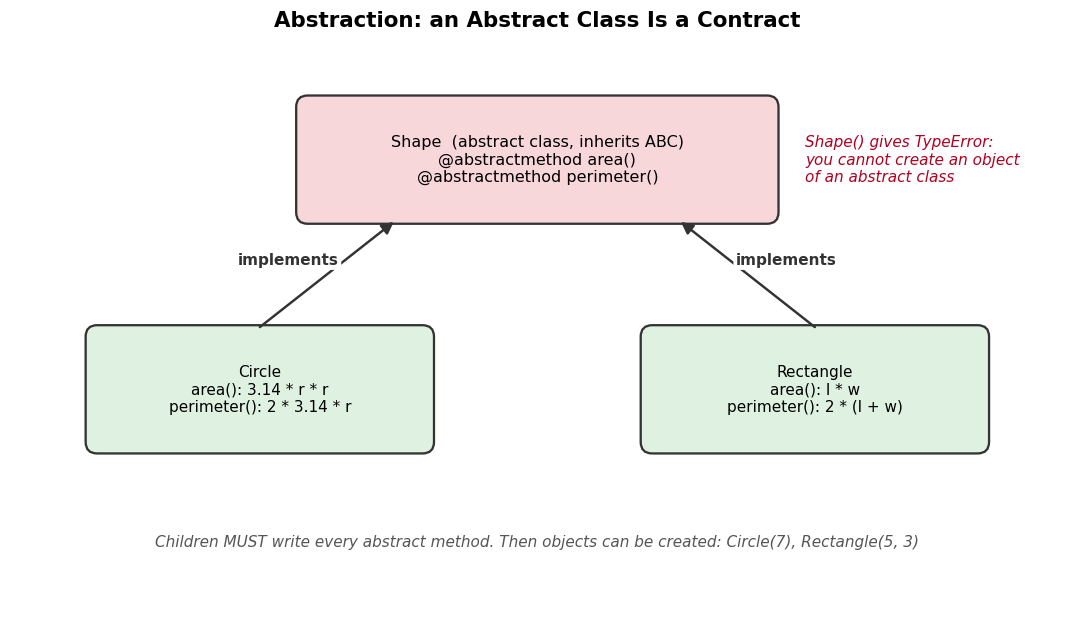

In [ ]:
# Example 1: Abstraction in everyday code - one simple method, the details are hidden
class CoffeeMachine:
    def make_coffee(self):             # the simple public method
        self.__boil_water()
        self.__grind_beans()
        self.__brew()
        print('Your coffee is ready!')

    def __boil_water(self):            # hidden details (private helper methods)
        print('  boiling water...')

    def __grind_beans(self):
        print('  grinding beans...')

    def __brew(self):
        print('  brewing...')

CoffeeMachine().make_coffee()
# Expected output:
#   boiling water...
#   grinding beans...
#   brewing...
# Your coffee is ready!

In [ ]:
# Example 2: An abstract class - a contract that every child class must follow
from abc import ABC, abstractmethod
import math

class Shape(ABC):
    def __init__(self, name):
        self.name = name

    @abstractmethod
    def area(self):
        pass                           # no body: each shape decides for itself

    @abstractmethod
    def perimeter(self):
        pass

    def describe(self):                # a normal method that all shapes share
        print(f'{self.name}: area = {self.area():.2f}, perimeter = {self.perimeter():.2f}')

class Circle(Shape):
    def __init__(self, radius):
        super().__init__('Circle')
        self.radius = radius

    def area(self):
        return math.pi * self.radius ** 2

    def perimeter(self):
        return 2 * math.pi * self.radius

class Rectangle(Shape):
    def __init__(self, length, width):
        super().__init__('Rectangle')
        self.length = length
        self.width = width

    def area(self):
        return self.length * self.width

    def perimeter(self):
        return 2 * (self.length + self.width)

for shape in [Circle(7), Rectangle(5, 3)]:
    shape.describe()
# Expected output:
# Circle: area = 153.94, perimeter = 43.98
# Rectangle: area = 15.00, perimeter = 16.00

In [ ]:
# Example 3: The rules of abstract classes
try:
    s = Shape('Mystery')
except TypeError as e:
    print('Error:', e)

class Triangle(Shape):                 # forgot to write perimeter()
    def __init__(self, base, height):
        super().__init__('Triangle')
        self.base = base
        self.height = height

    def area(self):
        return 0.5 * self.base * self.height

try:
    t = Triangle(4, 3)
except TypeError as e:
    print('Error:', e)
# Expected output (the wording is slightly different in older Python versions):
# Error: Can't instantiate abstract class Shape without an implementation for abstract methods 'area', 'perimeter'
# Error: Can't instantiate abstract class Triangle without an implementation for abstract method 'perimeter'

In [ ]:
# Example 4: Abstraction + polymorphism - a notification system
class Notifier(ABC):
    @abstractmethod
    def send(self, message):
        pass

class EmailNotifier(Notifier):
    def __init__(self, email):
        self.email = email

    def send(self, message):
        print(f'Email to {self.email}: {message}')

class SMSNotifier(Notifier):
    def __init__(self, phone):
        self.phone = phone

    def send(self, message):
        print(f'SMS to {self.phone}: {message[:20]}...')   # an SMS shows a short preview

def notify_all(notifiers, message):
    for n in notifiers:                # the caller only needs to know: it can send()
        n.send(message)

notify_all([EmailNotifier('asha@example.com'), SMSNotifier('98765-43210')],
           'Your order #1024 has been shipped')
# Expected output:
# Email to asha@example.com: Your order #1024 has been shipped
# SMS to 98765-43210: Your order #1024 has...

---
# Part 13: Quick Recap

| Concept | Syntax |
|---|---|
| Class | `class Student:` |
| Object | `s = Student('Asha', 20)` |
| Constructor | `def __init__(self, name, age):` |
| Instance attribute | `self.name = name` |
| Instance method | `def introduce(self):` |
| Class attribute | `school = 'GVS'` (in the class body) |
| Class method | `@classmethod` + `def f(cls):` |
| Static method | `@staticmethod` + `def f():` |
| Printable object | `def __str__(self): return ...` |
| Private attribute | `self.__balance` |
| Property | `@property` and `@marks.setter` |
| Inheritance | `class Dog(Animal):` |
| Parent's constructor | `super().__init__(...)` |
| Abstract class | `class Shape(ABC):` + `@abstractmethod` |

| Pillar | Remember it as |
|---|---|
| Encapsulation | Protect the data; change it only through methods |
| Inheritance | Reuse a parent class (**is a**) |
| Polymorphism | Same method name, different behaviour |
| Abstraction | Show what is needed, hide the details |

### Common beginner mistakes
1. **Forgetting `self`** as the first parameter of a method: `TypeError`.
2. **Writing `name` instead of `self.name`** inside a method.
3. **Misspelling `__init__`** (one underscore, or `__int__`): the attributes are never created.
4. **Forgetting `()` when creating an object**: `s = Student` stores the class, not an object.
5. **Forgetting `()` when calling a method**: `s.introduce` does not run it.
6. **Changing a class attribute through an object** (`s1.school = ...`): this creates a separate instance attribute.
7. **Using a list as a class attribute** when each object needs its own list.
8. **Forgetting `super().__init__()`** in a child's constructor: the parent's attributes are missing.
9. **Using `obj.__private` from outside the class**: `AttributeError`.
10. **Creating an object of an abstract class**, or not writing every abstract method: `TypeError`.
11. **Printing inside `__str__` instead of returning a string.**

---
# Part 14: Practice Exercises

Solve each exercise in the empty code cell below it. Each exercise shows the expected output.

### Exercise 1: Class and Objects

Create a `Book` class with a constructor that stores `title`, `author` and `pages`. Create two books and print them.

**Expected output:**
```
Python Basics by R. Sharma - 250 pages
Data Science 101 by P. Nair - 320 pages
```

In [ ]:
# Write your code here


### Exercise 2: Default Values in the Constructor

Create a `Mobile` class with `brand`, `price` and `colour` (default `'Black'`).

```python
m1 = Mobile('Samsung', 15000)
m2 = Mobile('Apple', 70000, 'White')
```
**Expected output:**
```
Samsung 15000 Black
Apple 70000 White
```

In [ ]:
# Write your code here


### Exercise 3: Methods That Return Values

Create a `Circle` class with `area()` and `circumference()` methods. Use `math.pi` and round the results to 2 decimal places.

```python
c = Circle(7)
print(c.area(), c.circumference())
```
**Expected output:**
```
153.94 43.98
```

In [ ]:
# Write your code here


### Exercise 4: Changing State

Create a `Counter` class with a `value` starting at 0 and the methods `increment()`, `decrement()` and `reset()`. `decrement()` must not go below 0; it prints `Cannot go below 0` instead.

```python
c = Counter()
c.increment(); c.increment(); c.increment(); c.decrement()
print(c.value)
c.reset()
c.decrement()
print(c.value)
```
**Expected output:**
```
2
Cannot go below 0
0
```

In [ ]:
# Write your code here


### Exercise 5: A List of Objects

Create an `Employee` class with `name` and `salary`. Make a list of three employees (Asha 50000, Ravi 42000, Meena 61000) and print the highest-paid employee and the total salary.

**Expected output:**
```
Highest paid: Meena (61000)
Total salary: 153000
```

In [ ]:
# Write your code here


### Exercise 6: Class Attributes

Create a `Product` class with two class attributes, `count = 0` and `TAX_PERCENT = 18`. The constructor stores `name` and `price` and increases `count`. Add a method `price_with_tax()`. Create three products, one of them `Product('Pen', 100)`.

**Expected output:**
```
Products created: 3
Pen with tax: 118.0
```

In [ ]:
# Write your code here


### Exercise 7: __str__

Create a `Point` class with `x` and `y`, a `__str__` method, and a method `distance_from_origin()` (use `math.sqrt`).

```python
p = Point(3, 4)
print(p)
print(p.distance_from_origin())
```
**Expected output:**
```
Point(3, 4)
5.0
```

In [ ]:
# Write your code here


### Exercise 8: Encapsulation

Create a `DebitCard` class with a **private** `__pin`. Add `check_pin(pin)`, which returns `True` or `False`, and `change_pin(old, new)`, which prints `PIN changed` or `Wrong old PIN`.

```python
card = DebitCard('1234')
print(card.check_pin('0000'))
card.change_pin('1234', '4321')
card.change_pin('1111', '2222')
print(card.check_pin('4321'))
```
**Expected output:**
```
False
PIN changed
Wrong old PIN
True
```

In [ ]:
# Write your code here


### Exercise 9: @property

Create a `Temperature` class with a `celsius` property. Its setter raises `ValueError` below -273.15. Add a read-only `fahrenheit` property (`F = C * 9 / 5 + 32`).

```python
t = Temperature(25)
print(t.fahrenheit)
t.celsius = 100
print(t.fahrenheit)
# then try t.celsius = -300 inside try-except
```
**Expected output:**
```
77.0
212.0
Error: temperature cannot be below -273.15
```

In [ ]:
# Write your code here


### Exercise 10: Inheritance and super()

Create a `Vehicle` class with `brand` and `wheels`, and a `describe()` method. Create `Bike(Vehicle)` and `Car(Vehicle)`, whose constructors take only `brand` and use `super()` to set 2 or 4 wheels.

**Expected output:**
```
Hero has 2 wheels
Tata has 4 wheels
```

In [ ]:
# Write your code here


### Exercise 11: Polymorphism

Create an `Employee` class with `name` and a method `calculate_pay()`. Create `FullTime(monthly_salary)` and `PartTime(hours, rate)`, each overriding `calculate_pay()`. Loop over a list of both kinds.

```python
staff = [FullTime('Asha', 40000), PartTime('Ravi', 80, 250)]
```
**Expected output:**
```
Asha (full-time): Rs. 40000
Ravi (part-time): Rs. 20000
```

In [ ]:
# Write your code here


### Exercise 12: Abstraction (Challenge)

Create an abstract class `Shape` with an abstract method `area()`. Create `Square(side)` and `Triangle(base, height)`. Show that `Shape()` raises `TypeError`, then print the total area of `[Square(4), Triangle(6, 4)]`.

**Expected output:**
```
Cannot create a Shape object
Total area: 28.0
```

In [ ]:
# Write your code here


---
# Part 15: Final Project - Library Management System

A small but real library system that lends **books, magazines and DVDs** to members, refuses invalid requests politely, calculates late fees, and keeps a log file.

**Where each concept is used**

| Concept | Where it is used |
|---|---|
| Classes, objects, constructor, `self` | every class |
| Class attributes | `LibraryItem.total_items`, `Member.MAX_ITEMS` |
| **Encapsulation** | private `__available`, `__borrowed`, `__items`; read-only properties |
| **Inheritance** | `Book`, `Magazine` and `DVD` inherit from `LibraryItem`; the custom exceptions inherit from `LibraryError` |
| **Polymorphism** | `loan_days()` and `late_fee()` give different answers for each item type, but the library calls them all the same way |
| **Abstraction** | `LibraryItem` is an abstract class; `Library` hides the details behind `lend()` and `receive()` |
| Earlier labs | dictionaries, lists, loops, functions with `*args`, custom exceptions, `try-except`, text files, an `input()` menu |

Build it step by step and **run every step in order**.

**Diagram: Library management system class design**

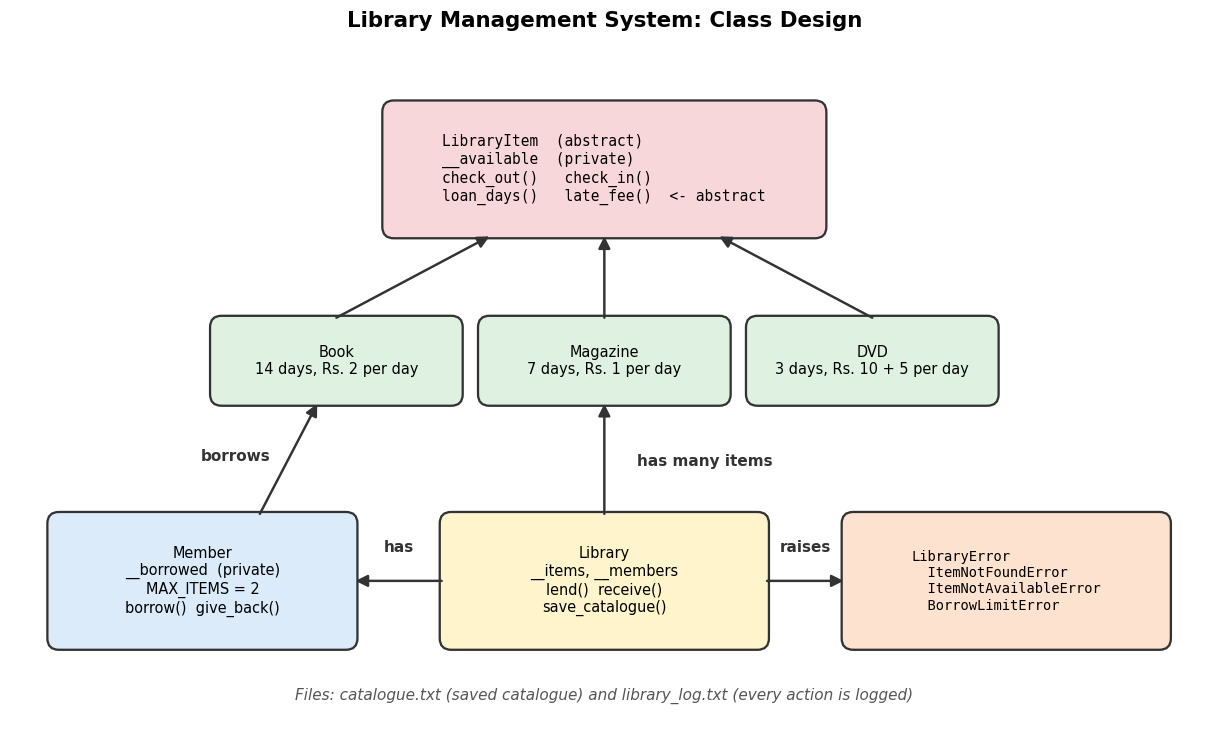

### Step 1: Custom Exceptions

One parent error and three specific children (Exception Handling lab).

In [ ]:
# Step 1: The library's own exception family
class LibraryError(Exception):
    pass          # parent: any library problem

class ItemNotFoundError(LibraryError):
    pass          # no item with that ID

class ItemNotAvailableError(LibraryError):
    pass          # the item is already borrowed

class BorrowLimitError(LibraryError):
    pass          # the member already has the maximum number of items

print('Exceptions ready')
# Expected output: Exceptions ready

### Step 2: The Abstract Parent Class

`LibraryItem` holds what every item shares. Its availability is **private** and can only change through `check_out()` and `check_in()` (**encapsulation**). The methods `loan_days()` and `late_fee()` are **abstract**: every item type must write its own (**abstraction**).

In [ ]:
# Step 2: Abstract base class for every library item
from abc import ABC, abstractmethod

class LibraryItem(ABC):
    """Abstract parent of every item that the library lends."""
    total_items = 0                      # class attribute: counts all items created

    def __init__(self, item_id, title):
        self.item_id = item_id
        self.title = title
        self.__available = True          # private: changed only by check_out() and check_in()
        LibraryItem.total_items += 1

    @property
    def is_available(self):              # read-only property
        return self.__available

    def check_out(self):
        if not self.__available:
            raise ItemNotAvailableError(f'{self.title} is already borrowed')
        self.__available = False

    def check_in(self):
        self.__available = True

    @abstractmethod
    def loan_days(self):                 # each item type decides
        pass

    @abstractmethod
    def late_fee(self, days_late):       # each item type decides
        pass

    def kind(self):
        return type(self).__name__        # 'Book', 'Magazine' or 'DVD'

    def __str__(self):
        status = 'Available' if self.__available else 'Borrowed'
        return f'[{self.item_id}] {self.kind():<8} {self.title:<22} {status}'

try:
    LibraryItem('X9', 'Mystery')
except TypeError as e:
    print('Error:', e)
# Expected output:
# Error: Can't instantiate abstract class LibraryItem without an implementation for abstract methods 'late_fee', 'loan_days'

### Step 3: Three Kinds of Items

Each child class calls `super().__init__()` (**inheritance**) and writes its own loan period and late fee (**polymorphism**).

In [ ]:
# Step 3: Concrete item classes
class Book(LibraryItem):
    def __init__(self, item_id, title, author):
        super().__init__(item_id, title)
        self.author = author

    def loan_days(self):
        return 14

    def late_fee(self, days_late):
        return days_late * 2              # Rs. 2 per day

class Magazine(LibraryItem):
    def __init__(self, item_id, title, issue):
        super().__init__(item_id, title)
        self.issue = issue

    def loan_days(self):
        return 7

    def late_fee(self, days_late):
        return days_late * 1              # Rs. 1 per day

class DVD(LibraryItem):
    def __init__(self, item_id, title, minutes):
        super().__init__(item_id, title)
        self.minutes = minutes

    def loan_days(self):
        return 3

    def late_fee(self, days_late):
        return 10 + days_late * 5         # Rs. 10 fixed + Rs. 5 per day

items = [Book('B1', 'Python Basics', 'R. Sharma'),
         Magazine('M1', 'Science Today', 'June 2026'),
         DVD('D1', 'Wildlife Documentary', 95)]
for item in items:
    print(item, '| loan:', item.loan_days(), 'days | 3 days late costs Rs.', item.late_fee(3))
print('Items created:', LibraryItem.total_items)
# Expected output:
# [B1] Book     Python Basics          Available | loan: 14 days | 3 days late costs Rs. 6
# [M1] Magazine Science Today          Available | loan: 7 days | 3 days late costs Rs. 3
# [D1] DVD      Wildlife Documentary   Available | loan: 3 days | 3 days late costs Rs. 25
# Items created: 3     (if you run this cell again, re-run Step 2 first to reset the count)

### Step 4: Members

A member's list of borrowed items is **private**. The `borrowed` property gives out a **copy**, so outside code cannot change the real list. `MAX_ITEMS` is a class attribute: the same rule for every member.

In [ ]:
# Step 4: The Member class
class Member:
    """A library member who can borrow up to MAX_ITEMS items."""
    MAX_ITEMS = 2                        # class attribute: the same limit for everyone

    def __init__(self, member_id, name):
        self.member_id = member_id
        self.name = name
        self.__borrowed = []             # private list of borrowed items

    @property
    def borrowed(self):
        return list(self.__borrowed)     # a copy, so outside code cannot change our list

    def borrow(self, item):
        if len(self.__borrowed) >= Member.MAX_ITEMS:
            raise BorrowLimitError(f'{self.name} already has {Member.MAX_ITEMS} items')
        item.check_out()                 # may raise ItemNotAvailableError
        self.__borrowed.append(item)

    def give_back(self, item):
        if item not in self.__borrowed:
            raise LibraryError(f'{self.name} did not borrow {item.title}')
        item.check_in()
        self.__borrowed.remove(item)

    def __str__(self):
        titles = []
        for item in self.__borrowed:
            titles.append(item.title)
        text = ', '.join(titles) if titles else 'nothing'
        return f'{self.name} ({self.member_id}) has: {text}'

asha = Member('L001', 'Asha')
asha.borrow(items[0])
print(asha)
print(items[0].is_available)
# items[0].is_available = True    # AttributeError: property 'is_available' of 'Book' object has no setter
asha.give_back(items[0])
print(asha)
print(items[0].is_available)
# Expected output:
# Asha (L001) has: Python Basics
# False
# Asha (L001) has: nothing
# True

### Step 5: The Library

The `Library` class keeps all the items and members in **private dictionaries**, writes every action to a **log file**, and offers two simple public methods, `lend()` and `receive()` (**abstraction**). Errors are not printed here; they are **raised**, so the caller decides what to do.

In [ ]:
# Step 5: The Library class
class Library:
    """Keeps all items and members, handles loans, and logs every action to a file."""
    def __init__(self, name, log_file='library_log.txt'):
        self.name = name
        self.log_file = log_file
        self.__items = {}                 # item_id -> item object
        self.__members = {}               # member_id -> member object
        with open(self.log_file, 'w', encoding='utf-8') as f:
            f.write(f'Log for {name}\n')

    def __log(self, message):             # private helper: add one line to the log
        with open(self.log_file, 'a', encoding='utf-8') as f:
            f.write(message + '\n')

    def __get_member(self, member_id):    # private helper
        if member_id not in self.__members:
            raise LibraryError(f'no member with id {member_id}')
        return self.__members[member_id]

    def add_item(self, item):
        self.__items[item.item_id] = item
        self.__log(f'ADDED {item.item_id} {item.title}')

    def add_member(self, member):
        self.__members[member.member_id] = member

    def find_item(self, item_id):
        try:
            return self.__items[item_id]
        except KeyError:
            raise ItemNotFoundError(f'no item with id {item_id}')

    def lend(self, member_id, item_id):
        member = self.__get_member(member_id)
        item = self.find_item(item_id)
        member.borrow(item)               # may raise BorrowLimitError or ItemNotAvailableError
        self.__log(f'LENT {item_id} to {member.name}')
        print(f'{member.name} borrowed {item.title} (due in {item.loan_days()} days)')

    def receive(self, member_id, item_id, days_late=0):
        member = self.__get_member(member_id)
        item = self.find_item(item_id)
        member.give_back(item)
        fee = item.late_fee(days_late) if days_late > 0 else 0     # polymorphism
        self.__log(f'RETURNED {item_id} by {member.name}, fee {fee}')
        print(f'{member.name} returned {item.title}. Late fee: Rs. {fee}')

    def show_catalogue(self):
        print(f'--- {self.name} catalogue ---')
        for item in self.__items.values():
            print(item)

    def show_members(self):
        for member in self.__members.values():
            print(member)

    def save_catalogue(self, filename='catalogue.txt'):
        with open(filename, 'w', encoding='utf-8') as f:
            for item in self.__items.values():
                f.write(f'{item.kind()},{item.item_id},{item.title},{item.is_available}\n')

print('Library class ready')
# Expected output: Library class ready

### Step 6: A Day at the Library

`safely()` runs any library action and turns every `LibraryError` into a friendly message. It receives a **method as an argument** and uses **`*args`** (Functions lab), and one `except LibraryError` catches all three child errors.

In [ ]:
# Step 6: Try the library with some good and some bad requests
def safely(action, *args):
    """Run a library action and report any LibraryError instead of crashing."""
    try:
        action(*args)
    except LibraryError as e:                 # catches every kind of LibraryError
        print(f'  {type(e).__name__}: {e}')

library = Library('City Library')
for item in [Book('B1', 'Python Basics', 'R. Sharma'),
             Book('B2', 'Data Science 101', 'P. Nair'),
             Magazine('M1', 'Science Today', 'June 2026'),
             DVD('D1', 'Wildlife Documentary', 95)]:
    library.add_item(item)
library.add_member(Member('L001', 'Asha'))
library.add_member(Member('L002', 'Ravi'))

safely(library.lend, 'L001', 'B1')
safely(library.lend, 'L002', 'B1')         # already borrowed by Asha
safely(library.lend, 'L001', 'D1')
safely(library.lend, 'L001', 'M1')         # Asha has reached the limit of 2
safely(library.lend, 'L002', 'X9')         # no such item
safely(library.receive, 'L001', 'D1', 2)   # returned 2 days late
safely(library.lend, 'L002', 'D1')
print()
library.show_catalogue()
library.show_members()
# Expected output:
# Asha borrowed Python Basics (due in 14 days)
#   ItemNotAvailableError: Python Basics is already borrowed
# Asha borrowed Wildlife Documentary (due in 3 days)
#   BorrowLimitError: Asha already has 2 items
#   ItemNotFoundError: no item with id X9
# Asha returned Wildlife Documentary. Late fee: Rs. 20
# Ravi borrowed Wildlife Documentary (due in 3 days)
#
# --- City Library catalogue ---
# [B1] Book     Python Basics          Borrowed
# [B2] Book     Data Science 101       Available
# [M1] Magazine Science Today          Available
# [D1] DVD      Wildlife Documentary   Borrowed
# Asha (L001) has: Python Basics
# Ravi (L002) has: Wildlife Documentary

### Step 7: Save the Catalogue and Read the Log

The File Handling lab in action: the catalogue is saved with mode `'w'`, and the log was built line by line with mode `'a'`.

In [ ]:
# Step 7: Files written by the library
library.save_catalogue()
print('catalogue.txt:')
with open('catalogue.txt', 'r', encoding='utf-8') as f:
    print(f.read(), end='')
print()
print('library_log.txt:')
with open('library_log.txt', 'r', encoding='utf-8') as f:
    print(f.read(), end='')
# Expected output:
# catalogue.txt:
# Book,B1,Python Basics,False
# Book,B2,Data Science 101,True
# Magazine,M1,Science Today,True
# DVD,D1,Wildlife Documentary,False
#
# library_log.txt:
# Log for City Library
# ADDED B1 Python Basics
# ADDED B2 Data Science 101
# ADDED M1 Science Today
# ADDED D1 Wildlife Documentary
# LENT B1 to Asha
# LENT D1 to Asha
# RETURNED D1 by Asha, fee 20
# LENT D1 to Ravi

### Step 8: The Librarian's Menu

The complete interactive program. It uses the `library` object from Step 6, so its current state carries on.

In [ ]:
# Step 8: Menu for the librarian (uses input)
def run_library(library):
    """A simple menu for the librarian."""
    while True:
        print()
        print('1. Catalogue  2. Members  3. Lend  4. Return  5. Save and exit')
        choice = input('Choose an option: ').strip()
        if choice == '1':
            library.show_catalogue()
        elif choice == '2':
            library.show_members()
        elif choice == '3':
            member_id = input('Member ID: ').strip().upper()
            item_id = input('Item ID: ').strip().upper()
            safely(library.lend, member_id, item_id)
        elif choice == '4':
            member_id = input('Member ID: ').strip().upper()
            item_id = input('Item ID: ').strip().upper()
            try:
                days_late = int(input('Days late (0 if on time): '))
            except ValueError:
                print('  Please enter a whole number')
                continue
            safely(library.receive, member_id, item_id, days_late)
        elif choice == '5':
            library.save_catalogue()
            print('Catalogue saved to catalogue.txt. Goodbye!')
            break
        else:
            print('  Invalid option, choose 1 to 5')

run_library(library)
# Example run:
#
# 1. Catalogue  2. Members  3. Lend  4. Return  5. Save and exit
# Choose an option: 4
# Member ID: l001
# Item ID: b1
# Days late (0 if on time): 5
# Asha returned Python Basics. Late fee: Rs. 10
#
# 1. Catalogue  2. Members  3. Lend  4. Return  5. Save and exit
# Choose an option: 3
# Member ID: L002
# Item ID: B1
# Ravi borrowed Python Basics (due in 14 days)
#
# 1. Catalogue  2. Members  3. Lend  4. Return  5. Save and exit
# Choose an option: 2
# Asha (L001) has: nothing
# Ravi (L002) has: Wildlife Documentary, Python Basics
#
# 1. Catalogue  2. Members  3. Lend  4. Return  5. Save and exit
# Choose an option: 5
# Catalogue saved to catalogue.txt. Goodbye!

### Make It Your Own

1. Add an `EBook` class that can be borrowed by any number of members at the same time
2. Add a `PremiumMember` class (inheritance) with `MAX_ITEMS = 5`
3. Add a menu option to add a new member or a new book
4. Load the catalogue back from `catalogue.txt` when the program starts (hint: a class method like `from_line()` in Part 6)
5. Add `__len__` to `Library` so that `len(library)` gives the number of items

---
### Well done!

You have completed the OOP lab. You can now design your own classes, protect their data, build families of classes with inheritance, and write code that works with many kinds of objects. This is how most real-world Python software is organised.